# Blindtrix Money_VN raw → M0 classification dataset

This notebook rebuilds the selected Blindtrix images directly from its Roboflow YOLO ZIP. It reads no existing `DATA` directory. Output is written to a timestamped folder under `C:\CS231_RAW_NOTEBOOK_RUNS`. The source YAML has nine labels; the six polymer denominations are retained. Selection is automatic from the raw image pool, followed by the small documented review decisions below.

In [1]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from collections import Counter
from datetime import datetime
from PIL import Image, ImageOps
from IPython.display import display
import pandas as pd
import numpy as np
import cv2
import yaml
import hashlib
import math
import re
import io
import matplotlib.pyplot as plt


In [2]:
RAW_ZIP = Path.home() / "Downloads" / "Money_VN_Regconization 2.v1i.yolov5pytorch.zip"
OUTPUT = Path(r"C:\CS231_RAW_NOTEBOOK_RUNS\blindtrix_v1") / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
OUTPUT.mkdir(parents=True)
TARGET_CLASSES = ["10000", "20000", "50000", "100000", "200000", "500000"]
assert RAW_ZIP.is_file(), f"Không tìm thấy ZIP: {RAW_ZIP}"
archive = ZipFile(RAW_ZIP)
members = set(archive.namelist())
print("ZIP:", RAW_ZIP, "\nOutput:", OUTPUT)


ZIP: Downloads/Money_VN_Regconization 2.v1i.yolov5pytorch.zip 
Output: C:\CS231_RAW_NOTEBOOK_RUNS\blindtrix_v1\20261025_182329_723653


In [3]:
config_member = ""
for name in sorted(members):
    if name.endswith("/data.yaml") or name == "data.yaml":
        config_member = name
        break
config = yaml.safe_load(archive.read(config_member).decode("utf-8-sig"))
class_names = config["names"]
class_to_vnd = {}
for class_id in range(len(class_names)):
    class_to_vnd[class_id] = re.sub(r"\D", "", str(class_names[class_id]))
class_rows = []
for class_id in class_to_vnd:
    class_rows.append({"class_id": class_id, "raw_class": class_names[class_id], "denomination": class_to_vnd[class_id], "used": class_to_vnd[class_id] in TARGET_CLASSES})
display(pd.DataFrame(class_rows))
image_members = []
for name in sorted(members):
    if "/images/" in name and Path(name).suffix.lower() in [".jpg", ".jpeg", ".png"]:
        image_members.append(name)
def label_for(image_member):
    label_name = image_member.replace("/images/", "/labels/")
    return label_name.rsplit(".", 1)[0] + ".txt"
missing_labels = []
for name in image_members:
    if label_for(name) not in members:
        missing_labels.append(name)
original_splits = Counter()
for name in image_members:
    original_splits[name.split("/images/")[0].split("/")[-1]] += 1
print("Images:", len(image_members), "| original splits:", dict(original_splits), "| missing labels:", len(missing_labels))
example = next((name for name in image_members if label_for(name) in members), "")
print("Example:", example, "| YOLO:", archive.read(label_for(example)).decode("utf-8-sig").strip())


,class_id,raw_class,denomination,used
0,0,1000,1000,False
1,1,10000,10000,True
2,2,100000,100000,True
3,3,2000,2000,False
4,4,20000,20000,True
5,5,200000,200000,True
6,6,5000,5000,False
7,7,50000,50000,True
8,8,500000,500000,True


Images: 8927 | original splits: {'test': 375, 'train': 8088, 'valid': 464} | missing labels: 0
Example: test/images/006769ea-071e-43ea-9165-7ed6cee7b9d6_jpg.rf.7899c8c4010ddb7e7c1978f805644444.jpg | YOLO: 8 0.509375 0.55859375 0.54609375 0.8828125


In [4]:
def source_name(member):
    name = re.sub(r"\.rf\.[0-9a-f]+$", "", Path(member).stem, flags=re.I)
    return re.sub(r"_(jpg|png|jpeg)$", "", name, flags=re.I)
def read_boxes(label_member):
    if label_member not in members:
        return []
    boxes = []
    for line in archive.read(label_member).decode("utf-8-sig").splitlines():
        values = line.split()
        if len(values) != 5:
            return []
        try:
            class_id = int(values[0]); x, y, w, h = map(float, values[1:])
        except ValueError:
            return []
        if class_id not in class_to_vnd or not all(math.isfinite(v) for v in (x, y, w, h)) or not 0 <= x <= 1 or not 0 <= y <= 1 or not 0 < w <= 1 or not 0 < h <= 1:
            return []
        boxes.append({"raw_label": class_to_vnd[class_id], "cx": x, "cy": y, "bw": w, "bh": h})
    return boxes
records = []
for member in image_members:
    boxes = read_boxes(label_for(member))
    try:
        with Image.open(io.BytesIO(archive.read(member))) as image:
            image.load(); width, height = image.size
        readable = True
    except Exception:
        width, height, readable = 0, 0, False
    valid = readable and len(boxes) == 1 and boxes[0]["raw_label"] in TARGET_CLASSES
    row = {"member": member, "path_order": member.replace("/", "\\"), "source_name": source_name(member), "annotation_member": label_for(member), "width": width, "height": height, "valid": valid, "is_variant": bool(re.search(r"\.rf\.[0-9a-f]+$", Path(member).stem, flags=re.I))}
    row.update(boxes[0] if len(boxes) == 1 else {"raw_label": "", "cx": 0, "cy": 0, "bw": 0, "bh": 0})
    records.append(row)
all_images = pd.DataFrame(records)
all_images = all_images.sort_values(["valid", "is_variant", "width", "path_order"], ascending=[False, True, False, True])
representatives = all_images.drop_duplicates("source_name")
pool = representatives[representatives["valid"]].copy().sort_values("path_order").reset_index(drop=True)
print("Raw files:", len(all_images), "→ canonical source groups:", len(representatives), "→ eligible representatives:", len(pool))
all_images.to_csv(OUTPUT / "01_ALL_RAW_IMAGES.csv", index=False)
display(pool.groupby("raw_label").size().reindex(TARGET_CLASSES).to_frame("eligible source groups"))


Raw files: 8927 → canonical source groups: 3496 → eligible representatives: 2000


,eligible source groups
raw_label,
10000,354
20000,359
50000,295
100000,276
200000,357
500000,359


In [5]:
# Blindtrix has no capture timestamps that define sequences, so each canonical source image is its own capture group.
pool["capture_group"] = pool["source_name"]
summaries = []
for row in pool.to_dict("records"):
    with Image.open(io.BytesIO(archive.read(row["member"]))) as image:
        gray = np.asarray(ImageOps.grayscale(image.resize((96, 96))), dtype=np.uint8)
    histogram = cv2.calcHist([gray], [0], None, [32], [0, 256]).ravel()
    p_hist = (histogram + 1e-9) / gray.size
    summaries.append({"box_area": row["bw"] * row["bh"], "brightness": float(gray.mean()), "contrast": float(gray.std()), "tone_detail": float(histogram.dot(-np.log2(p_hist))), "edge_fraction": float(np.mean(cv2.Canny(gray, 80, 160) > 0))})
pool = pd.concat([pool, pd.DataFrame(summaries)], axis=1)
pool.to_csv(OUTPUT / "02_CANDIDATES_FROM_RAW.csv", index=False)
pool = pd.read_csv(OUTPUT / "02_CANDIDATES_FROM_RAW.csv", keep_default_na=False, dtype={"raw_label": str, "source_name": str, "capture_group": str})
feature_columns = ["box_area", "bw", "bh", "cx", "cy", "brightness", "contrast", "tone_detail", "edge_fraction"]
def choose_different_images(group, limit=40, per_capture=20):
    group = group.sort_values("path_order").reset_index(drop=True)
    values = group[feature_columns].to_numpy(float)
    values = (values - values.min(axis=0)) / np.maximum(values.max(axis=0) - values.min(axis=0), 1e-9)
    chosen = [0]
    distances = np.sum((values - values[0]) ** 2, axis=1)
    capture_counts = Counter([group.iloc[0]["capture_group"]])
    while len(chosen) < min(limit, len(group)):
        scores = distances.copy()
        for i, capture in enumerate(group["capture_group"]):
            if capture_counts[capture] >= per_capture:
                scores[i] = -1
        scores[chosen] = -1
        if scores.max() < 0:
            break
        next_image = int(scores.argmax())
        chosen.append(next_image); capture_counts[group.iloc[next_image]["capture_group"]] += 1
        distances = np.minimum(distances, np.sum((values - values[next_image]) ** 2, axis=1))
    return group.iloc[chosen].copy()
sampled_groups = []
for label in TARGET_CLASSES:
    one_label = pool[pool["raw_label"] == label]
    sampled_groups.append(choose_different_images(one_label))
sampled = pd.concat(sampled_groups, ignore_index=True)
print("Selected before duplicate removal:", len(sampled), dict(sampled.groupby("raw_label").size()))
assert len(sampled) == 240


Selected before duplicate removal: 240 {'10000': np.int64(40), '100000': np.int64(40), '20000': np.int64(40), '200000': np.int64(40), '50000': np.int64(40), '500000': np.int64(40)}


In [6]:
def rotation_hashes(member):
    data = np.frombuffer(archive.read(member), dtype=np.uint8)
    gray = cv2.imdecode(data, cv2.IMREAD_GRAYSCALE)
    gray = cv2.resize(gray, (64, 64), interpolation=cv2.INTER_AREA)
    dhashes = []; phashes = []
    for rotation in range(4):
        rotated = np.rot90(gray, rotation).copy()
        small = cv2.resize(rotated, (9, 8), interpolation=cv2.INTER_AREA)
        dhashes.append(sum(int(small[y, x] > small[y, x + 1]) << (y * 8 + x) for y in range(8) for x in range(8)))
        small32 = cv2.resize(rotated, (32, 32), interpolation=cv2.INTER_AREA).astype(np.float32)
        frequencies = cv2.dct(small32)[:8, :8].reshape(-1)[1:]
        middle = np.median(frequencies)
        phashes.append(sum(int(value > middle) << i for i, value in enumerate(frequencies)))
    return min(dhashes), min(phashes)
image_hashes = [rotation_hashes(member) for member in pool["member"]]
parent = list(range(len(pool)))
def find_group(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]; i = parent[i]
    return i
def join_groups(i, j):
    left, right = find_group(i), find_group(j)
    if left != right: parent[right] = left
first_dhash = {}
for i, (dhash, phash) in enumerate(image_hashes):
    if dhash in first_dhash: join_groups(i, first_dhash[dhash])
    else: first_dhash[dhash] = i
    for j in range(i):
        if (phash ^ image_hashes[j][1]).bit_count() <= 4: join_groups(i, j)
group_by_member = {}
for i, member in enumerate(pool["member"]): group_by_member[member] = find_group(i)
sampled["duplicate_group"] = sampled["member"].map(group_by_member)
selected = sampled.sort_values("path_order").drop_duplicates("duplicate_group").copy()
duplicates = sampled[~sampled["member"].isin(selected["member"])].copy()
duplicates.to_csv(OUTPUT / "03_AUTOMATIC_DUPLICATE_REMOVALS.csv", index=False)
selected.to_csv(OUTPUT / "04_AUTOMATIC_SELECTION_BEFORE_REVIEW.csv", index=False)
print("Selected after rotation-aware duplicate removal:", len(selected))
assert len(selected) == 240


Selected after rotation-aware duplicate removal: 240


## Review decisions

The automatic sample above is constructed only from raw images and labels. Review decisions below are keyed by the SHA-256 of the source image bytes, so the decision cannot accidentally attach to a similarly named file. The two Blindtrix visual-QA decisions retained these images and corrected their denominations. No Blindtrix image was removed by the final visual-QA patch.

In [7]:
# Human visual review decisions from M0.3B.2: source hashes identify the reviewed raw examples.
CORRECT_LABEL_BY_SHA256 = {
    "bdb0c440dd565cd22fb735648cb6d462cabf0004a5c7f4f72312b7228838c17b": "200000",
    "a7daa85ba49333e26025f9bed8f2236d04aadd23ce7dc5c36e3e8f2932b7ad17": "200000",
    "7c04f0fc2dee654f0cb8d36ec0f5785072b2ea5b41c57ab6a820f87f4b64cb8f": "20000",
}
REMOVE_BY_SHA256 = {
    "945675af4ecd4c4791725e7e19bbc9d7c416cdcaf4249e585a04f7d393d17033": "HUMAN_REMOVE: visual review marked the image too blurred",
    "2dac19e610d99f9ea951aa2070b7a9144458fbdd98a2377f088e29fd3411d4f8": "HUMAN_REMOVE: visual review marked the image too blurred",
}
source_hashes = {}
for row in selected.to_dict("records"):
    source_hashes[row["member"]] = hashlib.sha256(archive.read(row["member"])).hexdigest()
review_remove_rows = []
for row in selected.to_dict("records"):
    if source_hashes[row["member"]] in REMOVE_BY_SHA256:
        review_remove_rows.append({"member": row["member"], "source_sha256": source_hashes[row["member"]], "reason": REMOVE_BY_SHA256[source_hashes[row["member"]]]})
selected = selected[~selected["member"].isin([row["member"] for row in review_remove_rows])].copy()
selected["source_image_sha256"] = selected["member"].map(source_hashes)
selected["final_label"] = selected["raw_label"]
for i, row in selected.iterrows():
    if row["source_image_sha256"] in CORRECT_LABEL_BY_SHA256:
        selected.at[i, "final_label"] = CORRECT_LABEL_BY_SHA256[row["source_image_sha256"]]
selected.to_csv(OUTPUT / "05_REVIEWED_SELECTION.csv", index=False)
pd.DataFrame(review_remove_rows).to_csv(OUTPUT / "05_REVIEW_REMOVALS.csv", index=False)
print("After review decisions:", len(selected), dict(selected.groupby("final_label").size()))
assert len(selected) == 238
assert selected.groupby("final_label").size().to_dict() == {"10000": 40, "20000": 38, "50000": 40, "100000": 40, "200000": 42, "500000": 38}


After review decisions: 238 {'10000': np.int64(40), '100000': np.int64(40), '20000': np.int64(38), '200000': np.int64(42), '50000': np.int64(40), '500000': np.int64(38)}


In [8]:
def pixel_bbox(row):
    width = int(row["width"]); height = int(row["height"])
    box = read_boxes(row["annotation_member"])[0]
    left = box["cx"] - box["bw"] / 2; top = box["cy"] - box["bh"] / 2
    right = box["cx"] + box["bw"] / 2; bottom = box["cy"] + box["bh"] / 2
    return max(0, math.floor(left * width)), max(0, math.floor(top * height)), min(width, math.ceil(right * width)), min(height, math.ceil(bottom * height))
def context_box(box, width, height):
    x1, y1, x2, y2 = box; bw = x2 - x1; bh = y2 - y1
    return max(0, round(x1 - .20 * bw)), max(0, round(y1 - .20 * bh)), min(width, round(x2 + .20 * bw)), min(height, round(y2 + .20 * bh))
selected["bbox"] = [pixel_bbox(row) for row in selected.to_dict("records")]
selected["bbox_short_side_px"] = [min(box[2]-box[0], box[3]-box[1]) for box in selected["bbox"]]
small = selected[selected["bbox_short_side_px"] < 120].copy()
small.to_csv(OUTPUT / "06_BELOW_120PX_REMOVALS.csv", index=False)
selected = selected[selected["bbox_short_side_px"] >= 120].copy()
print("BBox gate ≥120 px:", len(selected), "| below gate:", len(small))


BBox gate ≥120 px: 238 | below gate: 0


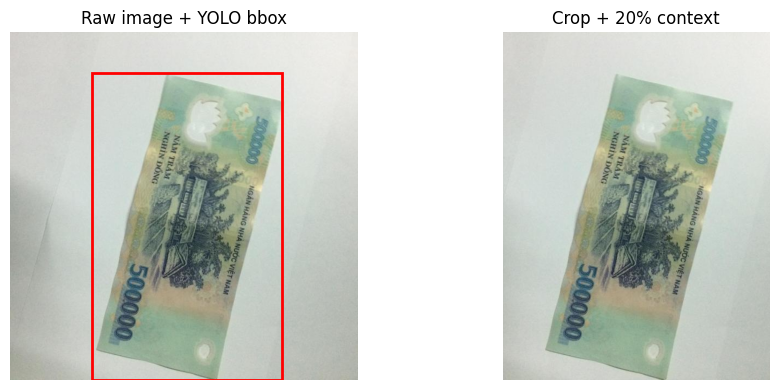

In [9]:
# Show the raw image and its YOLO box, then the 20% context crop.
demo = selected.iloc[0].to_dict()
with Image.open(io.BytesIO(archive.read(demo["member"]))) as image:
    image = image.convert("RGB"); crop_box = context_box(demo["bbox"], image.width, image.height); demo_crop = image.crop(crop_box)
fig, axes = plt.subplots(1, 2, figsize=(10, 4)); axes[0].imshow(image)
x1,y1,x2,y2 = demo["bbox"]; axes[0].add_patch(plt.Rectangle((x1,y1),x2-x1,y2-y1,fill=False,edgecolor="red",linewidth=2)); axes[0].set_title("Raw image + YOLO bbox"); axes[1].imshow(demo_crop); axes[1].set_title("Crop + 20% context")
for axis in axes: axis.axis("off")
plt.tight_layout(); plt.show()


In [10]:
DATA_OUT = OUTPUT / "BLINDTRIX_V1_CLASSIFICATION"
output_rows = []
rows_to_save = selected.sort_values(["final_label", "path_order"])
for row in rows_to_save.to_dict("records"):
    raw_bytes = archive.read(row["member"])
    with Image.open(io.BytesIO(raw_bytes)) as image:
        image = image.convert("RGB"); crop_box = context_box(row["bbox"], image.width, image.height); crop = image.crop(crop_box)
    relative_path = f"train/{row['final_label']}/BLINDTRIX_{row['source_name']}.png"
    target = DATA_OUT / relative_path; target.parent.mkdir(parents=True, exist_ok=True); crop.save(target, format="PNG", optimize=False)
    output_rows.append((row, raw_bytes, relative_path, crop_box, crop, target))
manifest_rows = []
for row, raw_bytes, relative_path, crop_box, crop, target in output_rows:
    manifest_rows.append({"relative_path": relative_path, "split": "train", "denomination": row["final_label"], "dataset_id": "blindtrix_v1", "source_name": row["source_name"], "source_archive_member": row["member"], "annotation_member": row["annotation_member"], "raw_label": row["raw_label"], "capture_group": row["capture_group"], "source_image_sha256": hashlib.sha256(raw_bytes).hexdigest(), "bbox_x1": row["bbox"][0], "bbox_y1": row["bbox"][1], "bbox_x2": row["bbox"][2], "bbox_y2": row["bbox"][3], "bbox_short_side_px": row["bbox_short_side_px"], "crop_x1": crop_box[0], "crop_y1": crop_box[1], "crop_x2": crop_box[2], "crop_y2": crop_box[3], "crop_width": crop.width, "crop_height": crop.height, "final_crop_sha256": hashlib.sha256(target.read_bytes()).hexdigest()})
result = pd.DataFrame(manifest_rows); result.to_csv(DATA_OUT / "manifest.csv", index=False)
assert len(result) == 238
assert len(result) == len(list(DATA_OUT.rglob("*.png")))
assert result.groupby("denomination").size().to_dict() == {"10000": 40, "20000": 38, "50000": 40, "100000": 40, "200000": 42, "500000": 38}
print("Exported:", len(result), "| split counts:", dict(result.groupby(["split", "denomination"]).size()))
with ZipFile(OUTPUT / "BLINDTRIX_V1_CLASSIFICATION.zip", "w", ZIP_DEFLATED) as package:
    for path in sorted(DATA_OUT.rglob("*")):
        if path.is_file(): package.write(path, path.relative_to(DATA_OUT).as_posix())
archive.close()
print("Dataset:", DATA_OUT, "| ZIP:", OUTPUT / "BLINDTRIX_V1_CLASSIFICATION.zip")


Exported: 238 | split counts: {('train', '10000'): np.int64(40), ('train', '100000'): np.int64(40), ('train', '20000'): np.int64(38), ('train', '200000'): np.int64(42), ('train', '50000'): np.int64(40), ('train', '500000'): np.int64(38)}


Dataset: C:\CS231_RAW_NOTEBOOK_RUNS\blindtrix_v1\20261025_182329_723653\BLINDTRIX_V1_CLASSIFICATION | ZIP: C:\CS231_RAW_NOTEBOOK_RUNS\blindtrix_v1\20261025_182329_723653\BLINDTRIX_V1_CLASSIFICATION.zip
